In [1]:
from pathlib import Path
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})

DATA_DIR = Path("../data")
csv_path = next(p for p in [DATA_DIR / "delivery_data.csv", DATA_DIR / "deliveries.csv"] if p.exists())

df = pd.read_csv(csv_path, parse_dates=["timestamp"])
df["date"] = df["timestamp"].dt.date
df["hour"] = df["timestamp"].dt.hour
df["delayed"] = df["delay_minutes"] > 0

print(f"Loaded {csv_path.name}: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Loaded deliveries.csv: 600 rows, 9 columns


,order_id,timestamp,zone,driver,volume,delay_minutes,date,hour,delayed
0,ORD-00001,2026-10-27 08:34:00,West,Ali,8.5,0,2026-10-27,8,False
1,ORD-00002,2026-10-27 08:54:00,North,Fatima,26.8,2,2026-10-27,8,True
2,ORD-00003,2026-10-27 09:06:00,North,Bilal,6.1,0,2026-10-27,9,False
3,ORD-00004,2026-10-27 10:32:00,West,Fatima,16.7,0,2026-10-27,10,False
4,ORD-00005,2026-10-27 10:49:00,North,Sana,11.9,6,2026-10-27,10,True


In [2]:
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate order ids:", int(df["order_id"].duplicated().sum()))
print("Date range:", df["timestamp"].min(), "to", df["timestamp"].max())
df[["volume", "delay_minutes"]].describe().round(2)

Missing values: 0
Duplicate order ids: 0
Date range: 2026-10-27 08:34:00 to 2026-11-25 20:57:00


,volume,delay_minutes
count,600.00,600.00
mean,9.98,5.87
std,6.61,5.44
min,1.00,0.00
25%,5.30,1.00
50%,8.75,5.00
75%,13.00,10.00
max,38.70,26.00


,orders,total_volume,avg_volume
zone,,,
Central,150,1527.7,10.2
North,140,1423.5,10.2
South,110,1075.5,9.8
East,111,1042.3,9.4
West,89,919.6,10.3


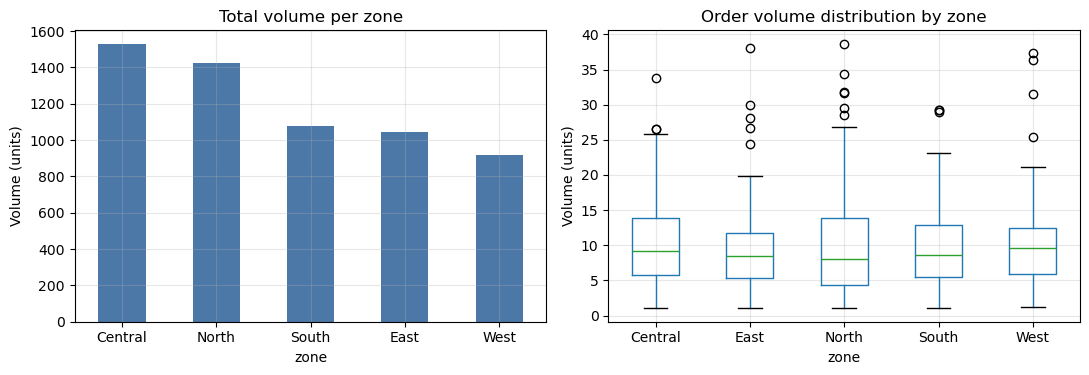

In [3]:
zone_stats = (
    df.groupby("zone")
    .agg(orders=("order_id", "count"), total_volume=("volume", "sum"), avg_volume=("volume", "mean"))
    .round(1)
    .sort_values("total_volume", ascending=False)
)
display(zone_stats)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
zone_stats["total_volume"].plot(kind="bar", ax=axes[0], color="#4C78A8", rot=0)
axes[0].set_title("Total volume per zone")
axes[0].set_ylabel("Volume (units)")

df.boxplot(column="volume", by="zone", ax=axes[1])
axes[1].set_title("Order volume distribution by zone")
axes[1].set_ylabel("Volume (units)")
plt.suptitle("")
plt.tight_layout()
plt.show()

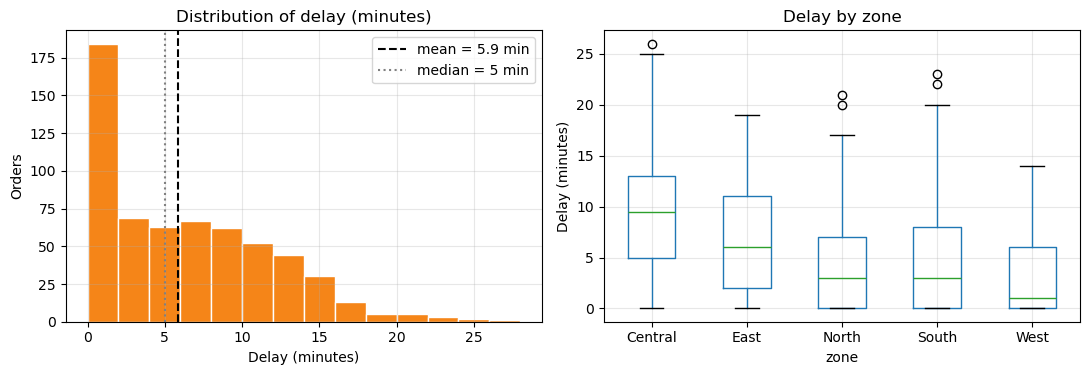

On time (0 min):      24.5%
Delayed (> 0 min):    75.5%
Seriously late (> 10): 21.2%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["delay_minutes"], bins=range(0, int(df["delay_minutes"].max()) + 3, 2), color="#F58518", edgecolor="white")
axes[0].axvline(df["delay_minutes"].mean(), color="black", linestyle="--", label=f"mean = {df['delay_minutes'].mean():.1f} min")
axes[0].axvline(df["delay_minutes"].median(), color="grey", linestyle=":", label=f"median = {df['delay_minutes'].median():.0f} min")
axes[0].set_title("Distribution of delay (minutes)")
axes[0].set_xlabel("Delay (minutes)")
axes[0].set_ylabel("Orders")
axes[0].legend()

df.boxplot(column="delay_minutes", by="zone", ax=axes[1])
axes[1].set_title("Delay by zone")
axes[1].set_ylabel("Delay (minutes)")
plt.suptitle("")
plt.tight_layout()
plt.show()

print(f"On time (0 min):      {(~df['delayed']).mean():.1%}")
print(f"Delayed (> 0 min):    {df['delayed'].mean():.1%}")
print(f"Seriously late (> 10): {(df['delay_minutes'] > 10).mean():.1%}")

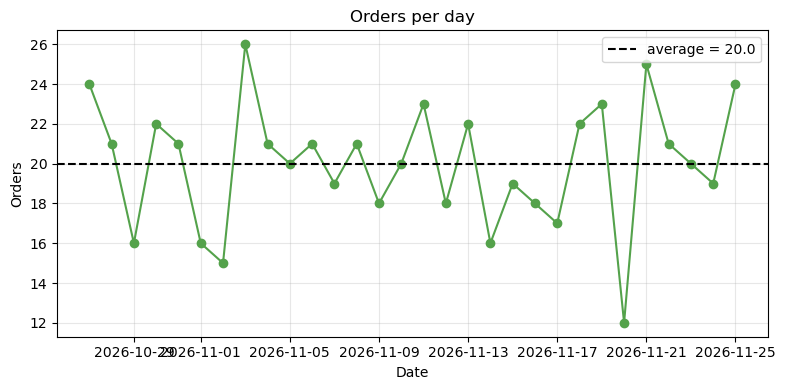

count    30.0
mean     20.0
std       3.2
min      12.0
25%      18.0
50%      20.5
75%      22.0
max      26.0
dtype: float64

In [5]:
daily = df.groupby("date").size()
ax = daily.plot(marker="o", color="#54A24B", title="Orders per day")
ax.axhline(daily.mean(), color="black", linestyle="--", label=f"average = {daily.mean():.1f}")
ax.set_xlabel("Date")
ax.set_ylabel("Orders")
ax.legend()
plt.tight_layout()
plt.show()

daily.describe().round(1)

In [6]:
DB_PATH = DATA_DIR / "deliveries.db"

sql_df = df[["order_id", "timestamp", "zone", "driver", "volume", "delay_minutes"]]

with sqlite3.connect(DB_PATH) as conn:
    sql_df.to_sql("deliveries", conn, if_exists="replace", index=False)
    count = conn.execute("SELECT COUNT(*) FROM deliveries").fetchone()[0]

print(f"Created {DB_PATH.name} with table 'deliveries' ({count} rows)")

Created deliveries.db with table 'deliveries' (600 rows)


In [7]:
def run_query(sql):
    with sqlite3.connect(DB_PATH) as conn:
        return pd.read_sql(sql, conn)

run_query("SELECT * FROM deliveries LIMIT 5")

,order_id,timestamp,zone,driver,volume,delay_minutes
0,ORD-00001,2026-10-27 08:34:00,West,Ali,8.5,0
1,ORD-00002,2026-10-27 08:54:00,North,Fatima,26.8,2
2,ORD-00003,2026-10-27 09:06:00,North,Bilal,6.1,0
3,ORD-00004,2026-10-27 10:32:00,West,Fatima,16.7,0
4,ORD-00005,2026-10-27 10:49:00,North,Sana,11.9,6


In [8]:
q1 = """
SELECT driver,
       COUNT(*)                         AS orders,
       ROUND(AVG(delay_minutes), 2)     AS avg_delay_min
FROM deliveries
GROUP BY driver
ORDER BY avg_delay_min DESC;
"""
q1_df = run_query(q1)
q1_df

,driver,orders,avg_delay_min
0,Hamza,79,6.53
1,Omar,73,6.38
2,Zara,75,6.29
3,Bilal,66,5.89
4,Sana,90,5.82
5,Fatima,80,5.61
6,Usman,68,5.35
7,Ali,69,4.97


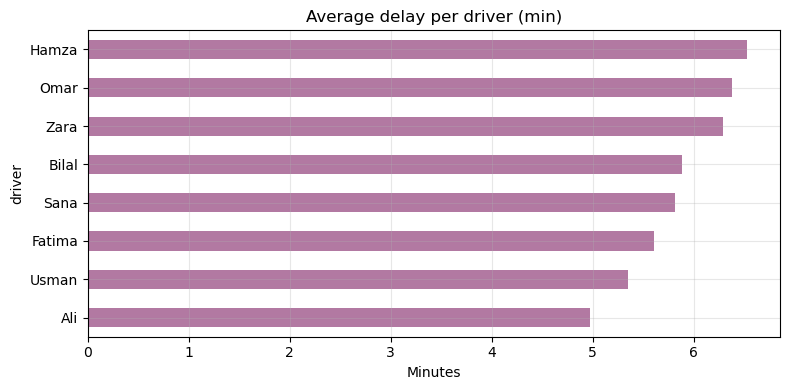

In [9]:
q1_df.sort_values("avg_delay_min").plot(kind="barh", x="driver", y="avg_delay_min", legend=False, color="#B279A2", title="Average delay per driver (min)")
plt.xlabel("Minutes")
plt.tight_layout()
plt.show()

In [10]:
q2 = """
SELECT CAST(strftime('%H', timestamp) AS INTEGER) AS hour,
       COUNT(*)                                   AS orders
FROM deliveries
GROUP BY hour
ORDER BY orders DESC;
"""
q2_df = run_query(q2)
print("Peak hour:", int(q2_df.iloc[0]["hour"]), "with", int(q2_df.iloc[0]["orders"]), "orders")
q2_df.head(5)

Peak hour: 13 with 57 orders


,hour,orders
0,13,57
1,11,55
2,17,52
3,9,50
4,20,47


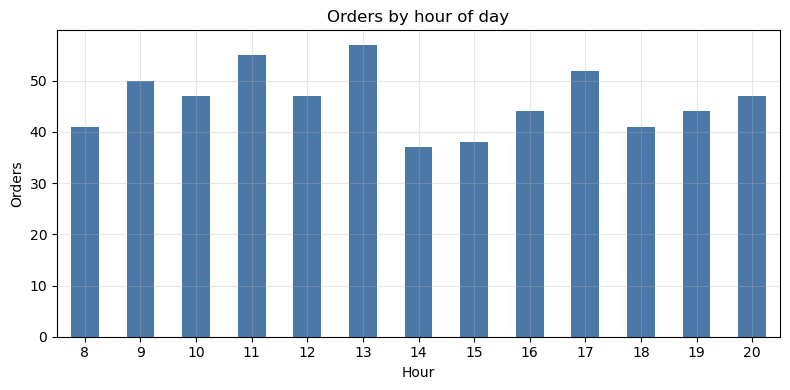

In [11]:
q2_df.sort_values("hour").plot(kind="bar", x="hour", y="orders", legend=False, color="#4C78A8", rot=0, title="Orders by hour of day")
plt.xlabel("Hour")
plt.ylabel("Orders")
plt.tight_layout()
plt.show()

In [12]:
q3 = """
SELECT zone,
       COUNT(*)                                                         AS orders,
       SUM(CASE WHEN delay_minutes > 0  THEN 1 ELSE 0 END)              AS delayed_orders,
       ROUND(100.0 * AVG(delay_minutes > 0), 1)                         AS pct_delayed,
       ROUND(100.0 * AVG(delay_minutes > 10), 1)                        AS pct_over_10_min
FROM deliveries
GROUP BY zone
ORDER BY pct_delayed DESC;
"""
q3_df = run_query(q3)
q3_df

,zone,orders,delayed_orders,pct_delayed,pct_over_10_min
0,Central,150,139,92.7,40.7
1,East,111,96,86.5,26.1
2,North,140,95,67.9,10.0
3,South,110,74,67.3,15.5
4,West,89,49,55.1,6.7


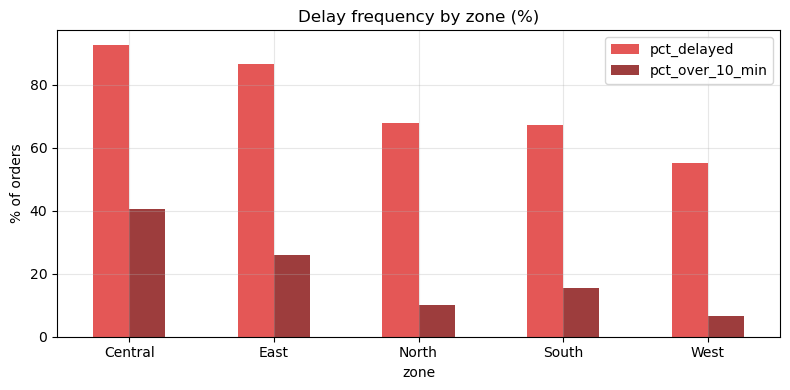

In [13]:
q3_df.plot(kind="bar", x="zone", y=["pct_delayed", "pct_over_10_min"], rot=0, title="Delay frequency by zone (%)", color=["#E45756", "#9D3D3D"])
plt.ylabel("% of orders")
plt.tight_layout()
plt.show()

Summary

| Question | Answer |
|---|---|
| Average delay per driver | Hamza is highest (6.53 min) and Ali is lowest (4.97 min). The spread is only about 1.5 minutes. |
| Peak delivery hour | 13:00 is the busiest hour (57 orders), followed by 11:00 (55) and 17:00 (52). |
| Zones with highest delay frequency | Central (92.7% delayed, 40.7% over 10 min) and East (86.5%, 26.1%) are the worst. West is best (55.1%, 6.7%). |